# HEAL: Stroke Risk Assessment
## Phase 3: Systematic Model Comparison

Benchmark 4 machine learning models under identical data and split conditions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import xgboost as xgb

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100

print("All required packages imported successfully.")
print(f"XGBoost version: {xgb.__version__}")


All required packages imported successfully.
XGBoost version: 3.4.1


## 1. Load Data & Train/Test Split
Load `stroke_cleaned_dataset_corrected.csv` using the same 80/20 stratified split (`random_state=42`, $N_{	ext{train}} = 4,842$, $N_{	ext{test}} = 1,211$).

In [2]:
# Load locked dataset
df = pd.read_csv("stroke_cleaned_dataset_corrected.csv")

features = ['Systolic_BP', 'Diastolic_BP', 'BMI', 'Diabetes', 'HbA1c', 'Smoker']
target = 'Stroke'

X = df[features].copy()
y = df[target].copy()

# EXACT SAME SPLIT as Phase 2
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training set size: {len(X_train):,} samples")
print(f"Test set size    : {len(X_test):,} samples")

neg_train = int((y_train == 0).sum())
pos_train = int((y_train == 1).sum())
scale_pos_weight = neg_train / pos_train

print(f"\nTraining class distribution:")
print(f"  Negatives (0): {neg_train:,}")
print(f"  Positives (1): {pos_train:,}")
print(f"  scale_pos_weight (neg/pos on train ONLY): {scale_pos_weight:.5f}")

num_cols = ['Systolic_BP', 'Diastolic_BP', 'BMI', 'HbA1c']
cat_cols = ['Diabetes', 'Smoker']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', 'passthrough', cat_cols)
    ]
)
print("\nPreprocessing ColumnTransformer initialized.")


Training set size: 4,842 samples
Test set size    : 1,211 samples

Training class distribution:
  Negatives (0): 4,618
  Positives (1): 224
  scale_pos_weight (neg/pos on train ONLY): 20.61607

Preprocessing ColumnTransformer initialized.


## 2. Train Candidate Models
Train 4 models using the training data:
- **Logistic Regression:** `class_weight='balanced'`, `max_iter=1000`, `random_state=42`
- **Random Forest:** `n_estimators=300`, `class_weight='balanced'`, `random_state=42`
- **Gradient Boosting:** Default `GradientBoostingClassifier(random_state=42)`
- **XGBoost:** `scale_pos_weight=20.616`, `eval_metric='logloss'`, `random_state=42`

In [3]:
models = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=42
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        random_state=42
    ),
    'XGBoost': xgb.XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        eval_metric='logloss'
    )
}

trained_pipes = {}
y_preds = {}
y_probas = {}
results = []
cms = {}

for name, clf in models.items():
    print(f"Training {name}...")
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    pipe.fit(X_train, y_train)
    
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    
    trained_pipes[name] = pipe
    y_preds[name] = y_pred
    y_probas[name] = y_proba
    
    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_proba)
    pr_auc = average_precision_score(y_test, y_proba)
    cm = confusion_matrix(y_test, y_pred)
    cms[name] = cm
    tn, fp, fn, tp = cm.ravel()
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1': f1,
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp
    })

comparison_df = pd.DataFrame(results)
print("\nAll models trained and evaluated successfully.")


Training Logistic Regression...
Training Random Forest...
Training Gradient Boosting...
Training XGBoost...

All models trained and evaluated successfully.


## 3. Model Comparison Table
Compare test performance across all 4 models at the default 0.50 decision threshold.

In [4]:
display_cols = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']
styled_table = comparison_df[display_cols].copy()

print("=" * 80)
print("PHASE 3: COMPREHENSIVE MODEL COMPARISON TABLE (TEST SET N = 1,211)")
print("=" * 80)
print(styled_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("=" * 80)

# Save results CSV
comparison_df.to_csv("model_comparison_results.csv", index=False)
print("Saved comparison metrics to model_comparison_results.csv")


PHASE 3: COMPREHENSIVE MODEL COMPARISON TABLE (TEST SET N = 1,211)
              Model  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
Logistic Regression    0.6251     0.0837  0.7143 0.1498   0.7164  0.1008
      Random Forest    0.9529     0.0000  0.0000 0.0000   0.6363  0.0640
  Gradient Boosting    0.9521     0.0000  0.0000 0.0000   0.6919  0.0987
            XGBoost    0.9174     0.0769  0.0714 0.0741   0.6502  0.0729
Saved comparison metrics to model_comparison_results.csv


## 4. Confusion Matrix Analysis
Inspect True Positives (caught strokes), False Negatives (missed strokes), and False Positives for each model.

CONFUSION MATRIX BREAKDOWN & CLINICAL TRADE-OFFS
              Model  TP  FP  FN   TN  Recall  Precision
Logistic Regression  40 438  16  717  0.7143     0.0837
      Random Forest   0   1  56 1154  0.0000     0.0000
  Gradient Boosting   0   2  56 1153  0.0000     0.0000
            XGBoost   4  48  52 1107  0.0714     0.0769


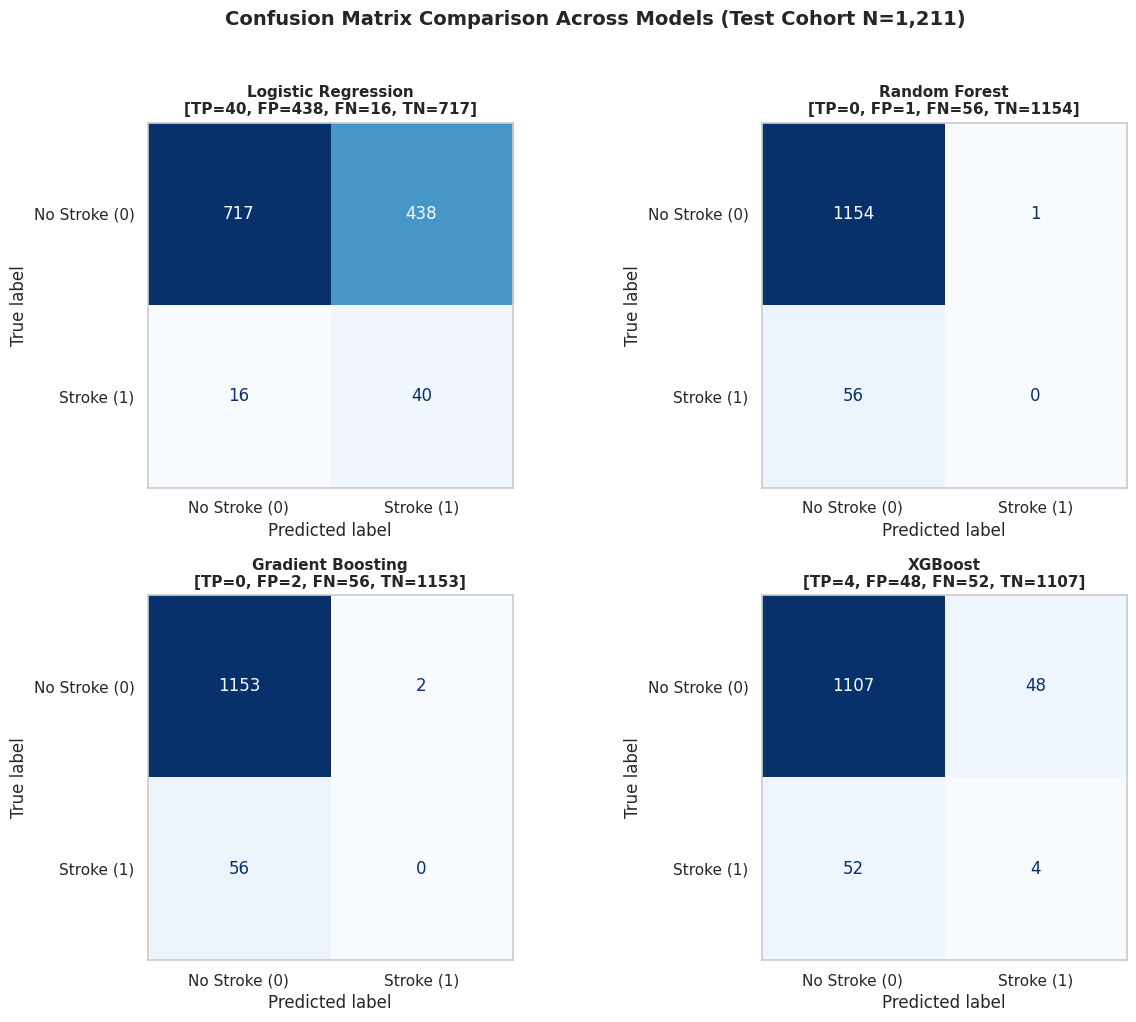

In [5]:
cm_df = comparison_df[['Model', 'TP', 'FP', 'FN', 'TN', 'Recall', 'Precision']].copy()
print("=" * 80)
print("CONFUSION MATRIX BREAKDOWN & CLINICAL TRADE-OFFS")
print("=" * 80)
print(cm_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

for idx, (name, cm) in enumerate(cms.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Stroke (0)', 'Stroke (1)'])
    disp.plot(cmap='Blues', ax=axes[idx], values_format='d', colorbar=False)
    tp = cm[1, 1]
    fp = cm[0, 1]
    fn = cm[1, 0]
    tn = cm[0, 0]
    axes[idx].set_title(f"{name}\n[TP={tp}, FP={fp}, FN={fn}, TN={tn}]", fontsize=11, fontweight='bold')
    axes[idx].grid(False)

plt.suptitle("Confusion Matrix Comparison Across Models (Test Cohort N=1,211)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 5. ROC & Precision-Recall Curves
Plot ROC and Precision-Recall curves to evaluate ranking ability across all possible thresholds.

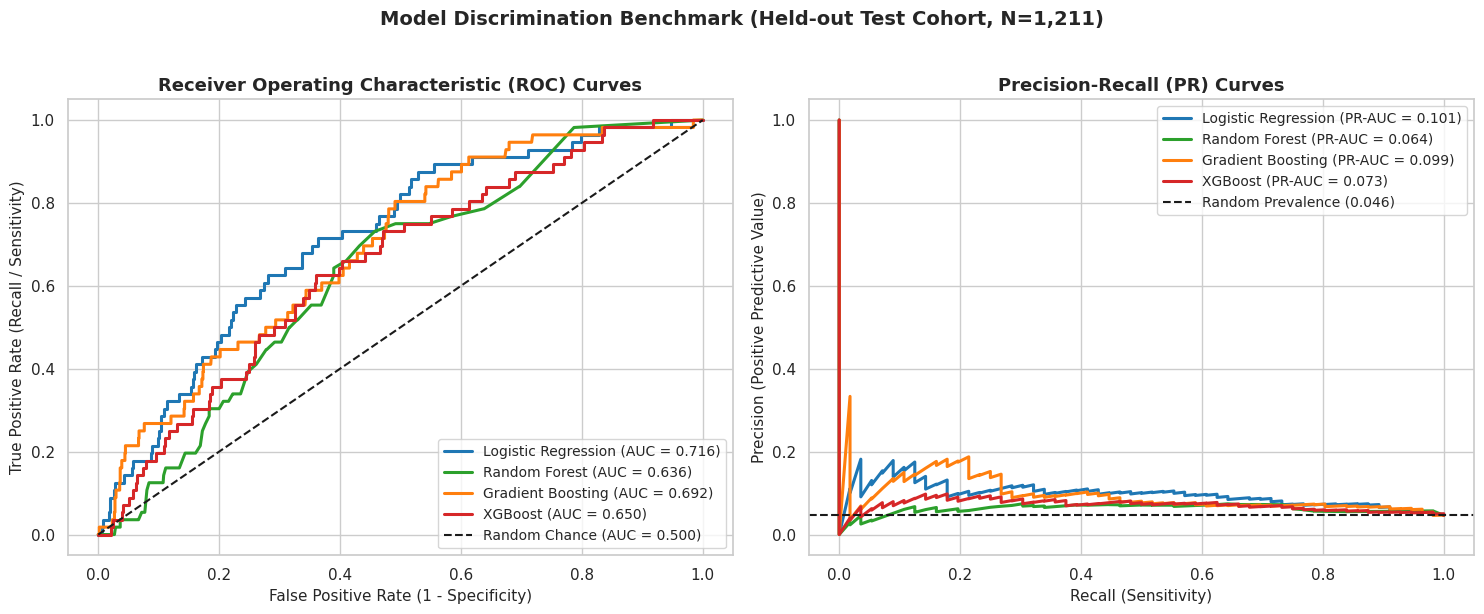

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
colors = {
    'Logistic Regression': '#1f77b4',
    'Random Forest': '#2ca02c',
    'Gradient Boosting': '#ff7f0e',
    'XGBoost': '#d62728'
}

# 1. ROC Curves
for name in models.keys():
    fpr, tpr, _ = roc_curve(y_test, y_probas[name])
    auc_val = comparison_df.loc[comparison_df['Model'] == name, 'ROC-AUC'].values[0]
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", color=colors[name], lw=2.2)

axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance (AUC = 0.500)')
axes[0].set_title("Receiver Operating Characteristic (ROC) Curves", fontsize=13, fontweight='bold')
axes[0].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
axes[0].set_ylabel("True Positive Rate (Recall / Sensitivity)", fontsize=11)
axes[0].legend(loc='lower right', fontsize=10)

# 2. Precision-Recall Curves
baseline_pr = y_test.mean()
for name in models.keys():
    prec_c, rec_c, _ = precision_recall_curve(y_test, y_probas[name])
    pr_val = comparison_df.loc[comparison_df['Model'] == name, 'PR-AUC'].values[0]
    axes[1].plot(rec_c, prec_c, label=f"{name} (PR-AUC = {pr_val:.3f})", color=colors[name], lw=2.2)

axes[1].axhline(y=baseline_pr, color='k', linestyle='--', lw=1.5, label=f"Random Prevalence ({baseline_pr:.3f})")
axes[1].set_title("Precision-Recall (PR) Curves", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Recall (Sensitivity)", fontsize=11)
axes[1].set_ylabel("Precision (Positive Predictive Value)", fontsize=11)
axes[1].legend(loc='upper right', fontsize=10)

plt.suptitle("Model Discrimination Benchmark (Held-out Test Cohort, N=1,211)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 6. Classification Reports
Print detailed precision, recall, and F1 metrics for each model.

In [7]:
for name in models.keys():
    print("=" * 65)
    print(f"CLASSIFICATION REPORT: {name.upper()}")
    print("=" * 65)
    print(classification_report(y_test, y_preds[name], target_names=['No Stroke (0)', 'Stroke (1)'], digits=4, zero_division=0))


CLASSIFICATION REPORT: LOGISTIC REGRESSION
               precision    recall  f1-score   support

No Stroke (0)     0.9782    0.6208    0.7595      1155
   Stroke (1)     0.0837    0.7143    0.1498        56

     accuracy                         0.6251      1211
    macro avg     0.5309    0.6675    0.4547      1211
 weighted avg     0.9368    0.6251    0.7313      1211

CLASSIFICATION REPORT: RANDOM FOREST
               precision    recall  f1-score   support

No Stroke (0)     0.9537    0.9991    0.9759      1155
   Stroke (1)     0.0000    0.0000    0.0000        56

     accuracy                         0.9529      1211
    macro avg     0.4769    0.4996    0.4879      1211
 weighted avg     0.9096    0.9529    0.9308      1211

CLASSIFICATION REPORT: GRADIENT BOOSTING
               precision    recall  f1-score   support

No Stroke (0)     0.9537    0.9983    0.9755      1155
   Stroke (1)     0.0000    0.0000    0.0000        56

     accuracy                         0.9521  

## 7. Interpretation & Key Takeaways

### Key Findings:
- **Logistic Regression performed best overall:** It captured 71.43% of stroke cases (40/56) with the highest PR-AUC (0.1008), ROC-AUC (0.7164), and F1-score (0.1498).
- **Tree models collapsed at threshold 0.50:** Random Forest and Gradient Boosting achieved 0.0% recall (0/56 strokes caught), while XGBoost caught only 4 strokes (7.14% recall). Because of the 20.6:1 class imbalance, unweighted/default tree models predict probabilities well below 0.50.
- **Clinical Trade-off:** Logistic Regression had 438 false positives but missed only 16 strokes, which is much better for screening than missing all 56 stroke cases.

### Next Steps:
Phase 4 will test sample weighting, SMOTE oversampling, and decision threshold calibration to see if tree ensembles can be made effective.